# 01 — Initial exploratory analysis

**Project:** How do cuisines differ and connect through their ingredients (network analysis) and through the language of recipes and reviews (NLP)?

**Data:** Food.com Recipes and Interactions (Majumder et al., EMNLP 2019), files `data/raw/RAW_recipes.csv` and `data/raw/RAW_interactions.csv`.

This notebook only *describes* the data. It does not clean or normalise anything yet. Every number below is computed from the files; where something cannot be computed, the notebook says so.

## 0. Setup
Imports, paths, and a common plot style. Every figure is saved to `figures/` as a PNG.

In [1]:
import ast
import re
import itertools
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import networkx as nx
from networkx.algorithms import bipartite
import nltk

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

# Plot style: light grid, one main colour, a second colour for highlights.
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9", "axes.labelcolor": INK,
    "text.color": INK, "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.titleweight": "bold", "axes.titlesize": 12,
})
pd.set_option("display.max_colwidth", 80)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    print(f"saved figures/{name}.png")

RNG_SEED = 42
print("pandas", pd.__version__, "| networkx", nx.__version__, "| nltk", nltk.__version__)

pandas 3.1.1 | networkx 3.7 | nltk 3.10.4


## 1. Load the raw files
We read both CSVs as they are. The columns `tags`, `ingredients`, `steps` and `nutrition` are stored as text that *looks like* a Python list (for example `"['salt', 'pepper']"`). We keep them as raw text for the duplicate checks in Section 2 and parse them in Section 3.

In [2]:
recipes = pd.read_csv(RAW / "RAW_recipes.csv")
reviews = pd.read_csv(RAW / "RAW_interactions.csv")
print("recipes:", recipes.shape, "| reviews (interactions):", reviews.shape)
recipes.head(3)

recipes: (231637, 12) | reviews (interactions): (1132367, 5)


,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'depending on size of squash , cut...",autumn is my favorite time of year to cook! this recipe \r\ncan be prepared ...,"['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'ol...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough into the bottom and sides of ...",this recipe calls for the crust to be prebaked a bit before adding ingredien...,"['prepared pizza crust', 'sausage patty', 'eggs', 'milk', 'salt and pepper',...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'main-dish', 'chili', 'crock-pot-s...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add chopped onions to ground beef when a...",this modified version of 'mom's' chili was a hit at our 2004 christmas party...,"['ground beef', 'yellow onions', 'diced tomatoes', 'tomato paste', 'tomato s...",13


In [3]:
reviews.head(3)

,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for 15 minutes.Added a shake of c...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall evening. Should have doubled ..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not quite a whole package (10oz) ...


## 2. Overview: columns, types, missing values, dates, duplicates

In [4]:
def overview(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(3),
        "n_unique": df.nunique(),
    })

print("RAW_recipes.csv")
display(overview(recipes))
print("RAW_interactions.csv")
display(overview(reviews))

RAW_recipes.csv


,dtype,n_missing,pct_missing,n_unique
name,str,1,0.000,230185
id,int64,0,0.000,231637
minutes,int64,0,0.000,888
contributor_id,int64,0,0.000,27926
submitted,str,0,0.000,5090
tags,str,0,0.000,209115
nutrition,str,0,0.000,229318
n_steps,int64,0,0.000,94
steps,str,0,0.000,231074
description,str,4979,2.149,222668


RAW_interactions.csv


,dtype,n_missing,pct_missing,n_unique
user_id,int64,0,0.000,226570
recipe_id,int64,0,0.000,231637
date,str,0,0.000,6396
rating,int64,0,0.000,6
review,str,169,0.015,1125282


**Dates.** `submitted` is the date a recipe was posted; `date` is the date of a review. We convert both to real dates and check their ranges.

In [5]:
recipes["submitted"] = pd.to_datetime(recipes["submitted"], errors="coerce")
reviews["date"] = pd.to_datetime(reviews["date"], errors="coerce")
print("unparseable dates:", recipes["submitted"].isna().sum(), "(recipes),", reviews["date"].isna().sum(), "(reviews)")
print("recipes submitted:", recipes["submitted"].min().date(), "to", recipes["submitted"].max().date())
print("reviews dated:    ", reviews["date"].min().date(), "to", reviews["date"].max().date())

unparseable dates: 0 (recipes), 0 (reviews)
recipes submitted: 1999-08-06 to 2018-12-04
reviews dated:     2000-01-25 to 2018-12-20


**Duplicates.** We check for repeated rows, repeated recipe ids, recipes with the same name, and users who reviewed the same recipe more than once. We also check that the two files link up: every review should point to a recipe that exists.

In [6]:
dup = {
    "identical recipe rows": recipes.duplicated().sum(),
    "repeated recipe ids": recipes["id"].duplicated().sum(),
    "recipes sharing a name with another recipe": recipes["name"].duplicated(keep=False).sum(),
    "identical review rows": reviews.duplicated().sum(),
    "repeated (user_id, recipe_id) pairs": reviews.duplicated(["user_id", "recipe_id"]).sum(),
    "reviews whose recipe_id is not in RAW_recipes": (~reviews["recipe_id"].isin(recipes["id"])).sum(),
    "recipes with no review at all": (~recipes["id"].isin(reviews["recipe_id"])).sum(),
}
pd.Series(dup, name="count").to_frame()

,count
identical recipe rows,0
repeated recipe ids,0
recipes sharing a name with another recipe,2881
identical review rows,0
"repeated (user_id, recipe_id) pairs",0
reviews whose recipe_id is not in RAW_recipes,0
recipes with no review at all,0


In [7]:
# Examples of recipes that share a name (different ids, probably different recipes)
recipes.loc[recipes["name"].duplicated(keep=False), ["id", "name", "submitted", "n_ingredients"]].sort_values("name").head(6)

,id,name,submitted,n_ingredients
846,470575,10 bean soup,2011-12-26,13
806,348965,10 bean soup,2009-01-11,14
1314,313237,3 bean baked beans,2008-07-11,12
1200,187438,3 bean baked beans,2006-09-24,11
1315,258846,3 bean salad,2007-10-13,9
1203,359316,3 bean salad,2009-03-05,10


## 3. Parse the list columns
`ast.literal_eval` safely turns the text `"['salt', 'pepper']"` into a real Python list. The 7 numbers in `nutrition` are, according to the dataset documentation, calories, total fat, sugar, sodium, protein, saturated fat and carbohydrates (all except calories in "% daily value").

We also check that the stored counts `n_ingredients` and `n_steps` match the length of the parsed lists.

In [8]:
LIST_COLS = ["tags", "ingredients", "steps", "nutrition"]
for col in LIST_COLS:
    recipes[col] = recipes[col].map(ast.literal_eval)

NUTRITION = ["calories", "total_fat_pdv", "sugar_pdv", "sodium_pdv", "protein_pdv", "sat_fat_pdv", "carbs_pdv"]
print("nutrition list lengths:", recipes["nutrition"].map(len).value_counts().to_dict())
nutr = pd.DataFrame(recipes["nutrition"].tolist(), columns=NUTRITION, index=recipes.index)
recipes = recipes.join(nutr)

print("n_ingredients == len(ingredients):", (recipes["n_ingredients"] == recipes["ingredients"].map(len)).mean().round(5))
print("n_steps == len(steps):            ", (recipes["n_steps"] == recipes["steps"].map(len)).mean().round(5))
print("recipes with an empty tag list:   ", (recipes["tags"].map(len) == 0).sum())
recipes[["name", "tags", "ingredients"]].head(3)

nutrition list lengths: {7: 231637}
n_ingredients == len(ingredients): 1.0
n_steps == len(steps):             1.0
recipes with an empty tag list:    0


,name,tags,ingredients
0,arriba baked winter squash mexican style,"[60-minutes-or-less, time-to-make, course, main-ingredient, cuisine, prepara...","[winter squash, mexican seasoning, mixed spice, honey, butter, olive oil, salt]"
1,a bit different breakfast pizza,"[30-minutes-or-less, time-to-make, course, main-ingredient, cuisine, prepara...","[prepared pizza crust, sausage patty, eggs, milk, salt and pepper, cheese]"
2,all in the kitchen chili,"[time-to-make, course, preparation, main-dish, chili, crock-pot-slow-cooker,...","[ground beef, yellow onions, diced tomatoes, tomato paste, tomato soup, rote..."


In [9]:
nutr.describe(percentiles=[0.5, 0.99]).T.round(1)

,count,mean,std,min,50%,99%,max
calories,231637.0,473.9,1189.7,0.0,313.4,3517.0,434360.2
total_fat_pdv,231637.0,36.1,77.8,0.0,20.0,302.0,17183.0
sugar_pdv,231637.0,84.3,800.1,0.0,25.0,1141.6,362729.0
sodium_pdv,231637.0,30.1,132.0,0.0,14.0,219.0,29338.0
protein_pdv,231637.0,34.7,58.5,0.0,18.0,188.0,6552.0
sat_fat_pdv,231637.0,45.6,98.2,0.0,23.0,404.0,10395.0
carbs_pdv,231637.0,15.6,81.8,0.0,9.0,154.0,36098.0


## 4. Recipes: ingredients, cooking time, steps
`minutes` contains some extreme values (Food.com users can type any number). We look at the quantiles first, then plot the bulk of the data and the full range on a log axis.

In [10]:
recipes[["n_ingredients", "minutes", "n_steps"]].describe(percentiles=[0.01, 0.5, 0.9, 0.99, 0.999]).T

,count,mean,std,min,1%,50%,90%,99%,99.9%,max
n_ingredients,231637.0,9.051153,3.734796e+00,1.0,3.0,9.0,14.0,20.00,26.0,4.300000e+01
minutes,231637.0,9398.546009,4.461963e+06,0.0,2.0,40.0,135.0,903.92,10095.0,2.147484e+09
n_steps,231637.0,9.765499,5.995128e+00,0.0,1.0,9.0,17.0,30.00,48.0,1.450000e+02


In [11]:
m = recipes["minutes"]
print("minutes == 0:            ", (m == 0).sum())
print("minutes > 1 day (1440):  ", (m > 1440).sum())
print("minutes > 30 days:       ", (m > 30 * 1440).sum())
print("minutes > 1 year:        ", (m > 365 * 1440).sum())
print("n_steps == 0:            ", (recipes["n_steps"] == 0).sum())
recipes.nlargest(3, "minutes")[["name", "minutes", "n_steps"]]

minutes == 0:             1094
minutes > 1 day (1440):   2000
minutes > 30 days:        70
minutes > 1 year:         2
n_steps == 0:             1


,name,minutes,n_steps
144074,no bake granola balls,2147483647,9
109624,how to preserve a husband,1051200,9
106563,homemade fruit liquers,288000,12


saved figures/01_recipe_distributions.png


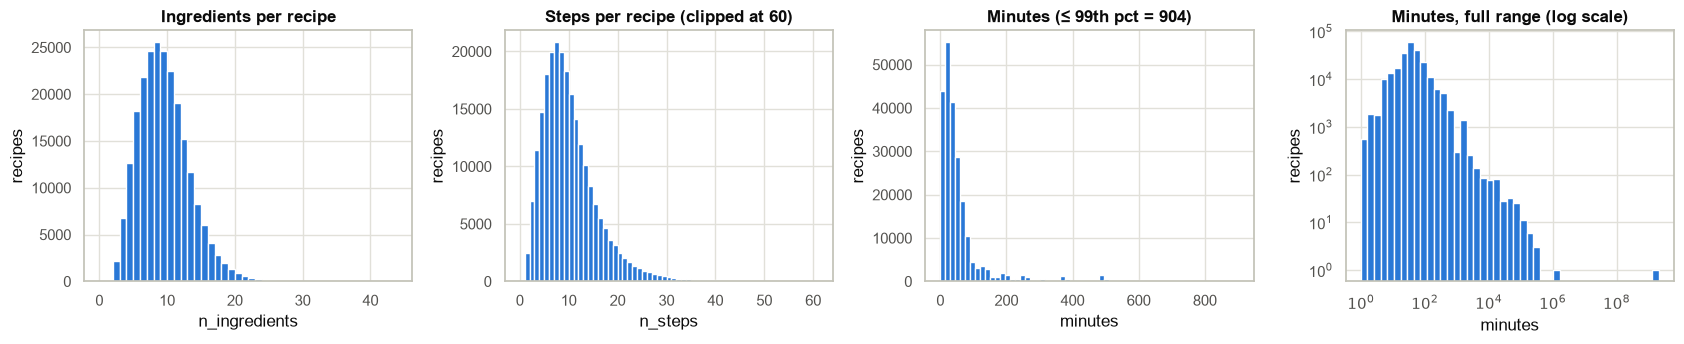

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))

axes[0].hist(recipes["n_ingredients"], bins=range(0, recipes["n_ingredients"].max() + 2), color=BLUE)
axes[0].set(title="Ingredients per recipe", xlabel="n_ingredients", ylabel="recipes")

axes[1].hist(recipes["n_steps"].clip(upper=60), bins=range(0, 62), color=BLUE)
axes[1].set(title="Steps per recipe (clipped at 60)", xlabel="n_steps", ylabel="recipes")

p99 = m.quantile(0.99)
axes[2].hist(m[m <= p99], bins=60, color=BLUE)
axes[2].set(title=f"Minutes (≤ 99th pct = {p99:.0f})", xlabel="minutes", ylabel="recipes")

axes[3].hist(np.log10(m[m > 0]), bins=45, color=BLUE)
axes[3].set(title="Minutes, full range (log scale)", xlabel="minutes", ylabel="recipes")
axes[3].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"$10^{{{v:.0f}}}$"))
axes[3].set_yscale("log")
fig.tight_layout()
save(fig, "01_recipe_distributions")
plt.show()

## 5. Reviews: ratings, reviews per recipe, review length, reviews per year
### 5.1 Ratings

,reviews,pct
rating,,
0,60847,5.37
1,12818,1.13
2,14123,1.25
3,40855,3.61
4,187360,16.55
5,816364,72.09


saved figures/02_rating_distribution.png


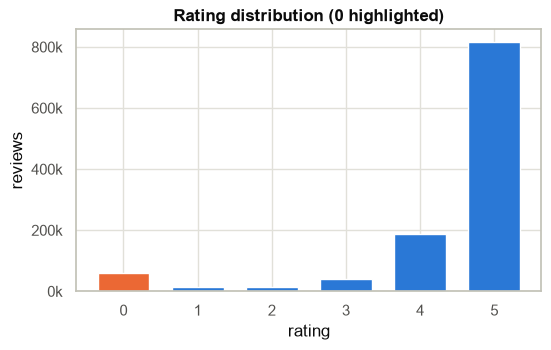

In [13]:
rating_counts = reviews["rating"].value_counts().sort_index()
display(pd.DataFrame({"reviews": rating_counts, "pct": (rating_counts / len(reviews) * 100).round(2)}))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(rating_counts.index, rating_counts.values, color=[ORANGE if r == 0 else BLUE for r in rating_counts.index], width=0.7)
ax.set(title="Rating distribution (0 highlighted)", xlabel="rating", ylabel="reviews")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1e3:.0f}k"))
save(fig, "02_rating_distribution")
plt.show()

**What does a rating of 0 mean?** Food.com's star scale is 1–5, so 0 is most likely "no stars given": a comment, a question, or a reply rather than a rating. We test that idea with a few signals: does the text contain a question mark, does it say the user has not made the recipe yet, and is the reviewer the recipe's own author (replying to comments)?

In [14]:
rv = reviews.merge(recipes[["id", "contributor_id"]], left_on="recipe_id", right_on="id", how="left")
text = rv["review"].fillna("").str.lower()
not_made = r"\b(?:haven'?t|have not|didn'?t|did not|not yet)\s+(?:made|tried|make|try)\b|\b(?:will|going to|gonna|can'?t wait to)\s+(?:try|make)\b"
signals = pd.DataFrame({
    "has '?'": text.str.contains("?", regex=False),
    "says not made / will try": text.str.contains(not_made, regex=True),
    "reviewer is the recipe author": rv["user_id"] == rv["contributor_id"],
    "mentions stars": text.str.contains(r"\bstars?\b", regex=True),
})
signals["is_zero"] = rv["rating"] == 0
(signals.groupby("is_zero").mean() * 100).round(1).rename(index={False: "rating 1–5 (%)", True: "rating 0 (%)"})

,has '?',says not made / will try,reviewer is the recipe author,mentions stars
is_zero,,,,
rating 1–5 (%),2.9,6.3,0.0,3.8
rating 0 (%),10.6,7.7,1.1,4.6


In [15]:
for t in rv.loc[rv["rating"] == 0, "review"].dropna().sample(8, random_state=RNG_SEED):
    print("-", t[:220].replace("\n", " "))

- I made this for the Summer 2007 Pick A Chef Contest.  I did not give this any stars since I messed it up by not cooking it long enough.  If it is any consolation, my neighbor still ate all of it that was cooked.  I am go
- I just made this recipe, followed it to a tee, and it is so runny that I'm baking it as brownies.  Will judge the taste after finishing.  How can cookies be made with these ingredients?
- Because of the problems I had with this recipe due to conversions from metric to US and also ingredient equivalents I am not going to rate it at this point.  Problem 1: I think that the puff pastry sheet may be a differe
- Awesome. I added 2 stalks of celery and a red bell pepper
- The last time I made this, my girlfriend advised me not to remove the ham fat after simmering it in the cider. I did it both ways, and it came out great each time.
- We really enjoyed this salad.  I used cranberry mustard, and added dried cranberries for colour.
- Good recipe .. Yummy :P :D
- Try whippi

### 5.2 Reviews per recipe and per user
Recipes that never got a review are counted as 0. The distribution is very skewed, so we use log–log axes.

reviews per recipe:


,count,mean,std,min,25%,50%,75%,90%,99%,max
value,231637.0,4.89,17.53,1.0,1.0,2.0,4.0,9.0,47.0,1613.0


reviews per user:


,count,mean,std,min,25%,50%,75%,90%,99%,max
value,226570.0,5.0,49.66,1.0,1.0,1.0,2.0,5.0,61.0,7671.0


recipes with ≥ 5 reviews: 53593 | ≥ 20 reviews: 7982
users who wrote exactly 1 review: 166256 (73.4% of 226570 users)


saved figures/03_reviews_per_recipe_user.png


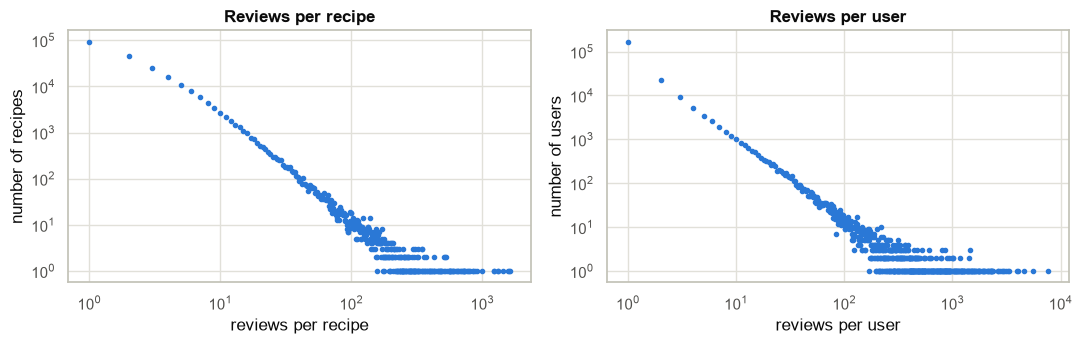

In [16]:
per_recipe = reviews.groupby("recipe_id").size().reindex(recipes["id"], fill_value=0)
per_user = reviews.groupby("user_id").size()
print("reviews per recipe:"); display(per_recipe.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(2).to_frame("value").T)
print("reviews per user:");   display(per_user.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(2).to_frame("value").T)
print("recipes with ≥ 5 reviews:", (per_recipe >= 5).sum(), "| ≥ 20 reviews:", (per_recipe >= 20).sum())
print("users who wrote exactly 1 review:", (per_user == 1).sum(), f"({(per_user == 1).mean():.1%} of {len(per_user)} users)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, s, what in [(axes[0], per_recipe, "recipe"), (axes[1], per_user, "user")]:
    vc = s[s > 0].value_counts().sort_index()
    ax.loglog(vc.index, vc.values, "o", ms=3, color=BLUE)
    ax.set(title=f"Reviews per {what}", xlabel=f"reviews per {what}", ylabel=f"number of {what}s")
fig.tight_layout()
save(fig, "03_reviews_per_recipe_user")
plt.show()

### 5.3 Review length
Length in words (split on whitespace).

,count,mean,std,min,1%,25%,50%,75%,99%,max
words,1132367.0,52.0,37.1,0.0,3.0,27.0,44.0,67.0,182.0,1182.0


reviews with 0 words (missing or empty text): 172
median words by rating: {0: 37.0, 1: 38.0, 2: 43.0, 3: 48.0, 4: 47.0, 5: 44.0}
saved figures/04_review_length.png


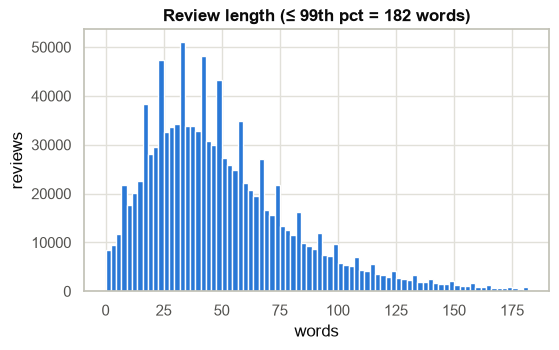

In [17]:
reviews["n_words"] = reviews["review"].fillna("").str.split().str.len()
display(reviews["n_words"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(1).to_frame("words").T)
print("reviews with 0 words (missing or empty text):", (reviews["n_words"] == 0).sum())
print("median words by rating:", reviews.groupby("rating")["n_words"].median().to_dict())

fig, ax = plt.subplots(figsize=(6, 3.4))
cap = reviews["n_words"].quantile(0.99)
ax.hist(reviews.loc[reviews["n_words"] <= cap, "n_words"], bins=80, color=BLUE)
ax.set(title=f"Review length (≤ 99th pct = {cap:.0f} words)", xlabel="words", ylabel="reviews")
save(fig, "04_review_length")
plt.show()

### 5.4 Activity over time
Reviews per year, next to recipes submitted per year.

,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
reviews,0,108,2904,20922,32961,45950,66643,89794,141158,167295,159445,107409,72147,56410,49488,30503,23374,18147,27062,20647
recipes submitted,2054,1038,4682,20056,18000,16601,23865,27260,34299,30745,22547,11902,7573,5187,3792,1049,306,204,288,189


saved figures/05_activity_per_year.png


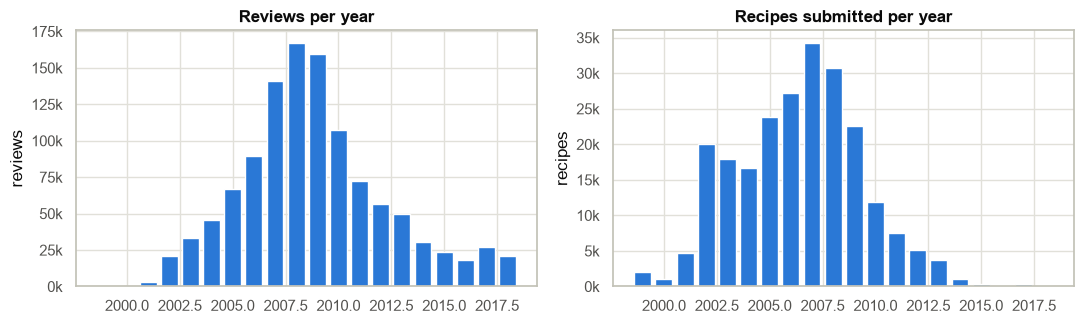

In [18]:
per_year = pd.DataFrame({
    "reviews": reviews["date"].dt.year.value_counts().sort_index(),
    "recipes submitted": recipes["submitted"].dt.year.value_counts().sort_index(),
}).fillna(0).astype(int)
display(per_year.T)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
axes[0].bar(per_year.index, per_year["reviews"], color=BLUE)
axes[0].set(title="Reviews per year", ylabel="reviews")
axes[1].bar(per_year.index, per_year["recipes submitted"], color=BLUE)
axes[1].set(title="Recipes submitted per year", ylabel="recipes")
for ax in axes:
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1e3:.0f}k"))
fig.tight_layout()
save(fig, "05_activity_per_year")
plt.show()

## 6. Cuisine tags (the most important part)
### 6.1 The most frequent tags
Each recipe has a list of tags. Many are generic (time, course, diet).

In [19]:
tag_counts = Counter(t for tags in recipes["tags"] for t in set(tags))
tag_counts = pd.Series(tag_counts).sort_values(ascending=False)
print("distinct tags:", len(tag_counts))
print("tags per recipe:", recipes["tags"].map(len).describe()[["mean", "50%", "max"]].round(1).to_dict())
tag_counts.head(40).to_frame("recipes").T

distinct tags: 552
tags per recipe: {'mean': 17.9, '50%': 17.0, 'max': 73.0}


,preparation,time-to-make,course,main-ingredient,dietary,easy,occasion,cuisine,low-in-something,main-dish,...,5-ingredients-or-less,holiday-event,inexpensive,low-protein,low-saturated-fat,fruit,oven,american,eggs-dairy,pasta-rice-and-grains
recipes,230546,225326,218148,170446,165091,126062,114145,91165,85776,71786,...,35466,34920,32619,32522,31378,31324,31180,31179,30142,27084


### 6.2 Discovering cuisine tags from the data
Food.com tags are hierarchical: a recipe tagged `italian` is also tagged `european` and `cuisine`. So instead of guessing a list of cuisines, we let the data tell us:

1. **Candidate cuisine tags** = tags whose recipes (almost) always also carry the parent tag `cuisine`: P(`cuisine` | tag) ≥ 0.95, and at least 5 recipes.
2. **Hierarchy** = tag A is a *parent* of tag B if A is more frequent than B and P(A | B) ≥ 0.95 (almost every B recipe is also an A recipe). For example, `european` should come out as a parent of `italian`.
3. A recipe's **specific cuisine(s)** = its cuisine tags after removing every tag that is only there as a parent of another tag on the same recipe.

In [20]:
has_cuisine = recipes["tags"].map(lambda ts: "cuisine" in ts)
with_cuisine = pd.Series(Counter(t for tags in recipes.loc[has_cuisine, "tags"] for t in set(tags)))
p_cuisine = (with_cuisine.reindex(tag_counts.index, fill_value=0) / tag_counts).drop("cuisine")
candidates = p_cuisine[(p_cuisine >= 0.95) & (tag_counts.reindex(p_cuisine.index) >= 5)].index.tolist()
print(f"{len(candidates)} candidate tags with P(cuisine | tag) >= 0.95")
print("next-best tags below the threshold:", p_cuisine.drop(candidates)[tag_counts.drop("cuisine") >= 20].nlargest(6).round(2).to_dict())

109 candidate tags with P(cuisine | tag) >= 0.95
next-best tags below the threshold: {'soul': 0.92, 'cinco-de-mayo': 0.89, 'gumbo': 0.87, 'ramadan': 0.82, 'eggplant': 0.79, 'stir-fry': 0.79}


One candidate is not a cuisine but a holiday: `chinese-new-year` (it inherits the `cuisine` tag from `chinese`). We remove it by hand; it is the only manual decision in this section. The tags just below the threshold (`soul`, `gumbo`, `curries`, ...) are dishes or styles, not tags in the cuisine branch, so the threshold separates the branch cleanly.

In [21]:
NOT_CUISINE = {"chinese-new-year"}
cuisine_tags = [t for t in candidates if t not in NOT_CUISINE]
cuisine_set = set(cuisine_tags)

# Parent relations between cuisine tags
pair_counts = Counter()
for tags in recipes.loc[has_cuisine, "tags"]:
    cs = [t for t in set(tags) if t in cuisine_set]
    pair_counts.update(itertools.permutations(cs, 2))
parents = defaultdict(set)
for (a, b), k in pair_counts.items():
    if tag_counts[a] > tag_counts[b] and k / tag_counts[b] >= 0.95:
        parents[b].add(a)
ancestor_tags = set().union(*parents.values())

def level(t):  # 1 = directly under 'cuisine'
    return 1 + max((level(p) for p in parents[t]), default=0)

ctab = pd.DataFrame({
    "recipes": tag_counts[cuisine_tags],
    "level": [level(t) for t in cuisine_tags],
    "parents": [", ".join(sorted(parents[t], key=lambda p: -tag_counts[p])) for t in cuisine_tags],
    "is_parent_of_others": [t in ancestor_tags for t in cuisine_tags],
})
print(f"{len(cuisine_tags)} cuisine/region tags. Recipes per level-1 tag:")
display(ctab[ctab["level"] == 1].sort_values("recipes", ascending=False))

108 cuisine/region tags. Recipes per level-1 tag:


,recipes,level,parents,is_parent_of_others
north-american,48479,1,,True
european,24912,1,,True
asian,13485,1,,True
mexican,6694,1,,True
south-west-pacific,3934,1,,True
african,2851,1,,True
australian,2845,1,,False
indian,2708,1,,False
middle-eastern,2067,1,,True
south-american,1255,1,,True


In [22]:
# Most frequent level-2+ (national or sub-regional) tags
ctab[ctab["level"] >= 2].sort_values("recipes", ascending=False).head(25)

,recipes,level,parents,is_parent_of_others
american,31179,2,north-american,True
italian,7410,2,european,False
southern-united-states,7114,3,"north-american, american",True
canadian,4572,2,north-american,True
southwestern-united-states,3536,3,"north-american, american",True
midwestern,2884,3,"north-american, american",False
northeastern-united-states,2566,3,"north-american, american",True
greek,2391,2,european,False
french,2268,2,european,False
chinese,2008,2,asian,True


Note that some cuisines that we would call "national" sit directly under `cuisine` with no region above them (for example `mexican` and `indian`), while others sit under a region (`italian` under `european`). The site's hierarchy is not perfectly consistent, which is one more reason to work with the *specific* tag of each recipe.

### 6.3 How many cuisines does each recipe have?

In [23]:
def specific_cuisines(tags):
    cs = {t for t in tags if t in cuisine_set}
    implied = set().union(*(parents[t] for t in cs)) if cs else set()
    return sorted(cs - implied)

recipes["cuisine_tags"] = recipes["tags"].map(lambda ts: sorted(t for t in ts if t in cuisine_set))
recipes["specific_cuisines"] = recipes["tags"].map(specific_cuisines)
recipes["n_specific"] = recipes["specific_cuisines"].map(len)

n_spec = recipes["n_specific"].clip(upper=2).map({0: "none", 1: "exactly one", 2: "two or more"})
summary = n_spec.value_counts().reindex(["none", "exactly one", "two or more"]).to_frame("recipes")
summary["pct"] = (summary["recipes"] / len(recipes) * 100).round(1)
display(summary)
print("recipes with the 'cuisine' tag but no cuisine tag below it:",
      (has_cuisine & (recipes["cuisine_tags"].map(len) == 0)).sum())
print("raw number of cuisine-branch tags per tagged recipe (parents included):",
      recipes.loc[recipes["cuisine_tags"].map(len) > 0, "cuisine_tags"].map(len).value_counts().sort_index().to_dict())

,recipes,pct
n_specific,,
none,140551,60.7
exactly one,69978,30.2
two or more,21108,9.1


recipes with the 'cuisine' tag but no cuisine tag below it: 80
raw number of cuisine-branch tags per tagged recipe (parents included): {1: 16056, 2: 48582, 3: 17203, 4: 6074, 5: 2182, 6: 622, 7: 191, 8: 77, 9: 55, 10: 24, 11: 4, 12: 5, 13: 4, 14: 3, 15: 1, 17: 2, 18: 1}


In [24]:
# The most common combinations among recipes with two or more specific cuisines
Counter(tuple(c) for c in recipes.loc[recipes["n_specific"] >= 2, "specific_cuisines"]).most_common(12)

[(('mexican', 'north-american'), 4517),
 (('asian', 'indian'), 2090),
 (('australian', 'south-west-pacific'), 1892),
 (('caribbean', 'central-american'), 925),
 (('asian', 'middle-eastern'), 508),
 (('mexican', 'tex-mex'), 477),
 (('mexican', 'southwestern-united-states'), 336),
 (('american', 'italian'), 327),
 (('american', 'canadian'), 317),
 (('european', 'north-american'), 268),
 (('cajun', 'creole'), 254),
 (('hawaiian', 'south-west-pacific'), 225)]

Most "two or more" recipes are not true fusion dishes: the most common pairs are a country plus a region that the 0.95 rule did not recognise as its parent (for example `mexican` + `north-american`, `indian` + `asian`). Among the shortlisted cuisines below, overlap is small.

In [25]:
# The most common specific cuisines (each recipe counted once per specific tag)
spec_counts = pd.Series(Counter(c for cs in recipes["specific_cuisines"] for c in cs)).sort_values(ascending=False)
only_counts = pd.Series(Counter(cs[0] for cs in recipes.loc[recipes["n_specific"] == 1, "specific_cuisines"]))
spec_table = pd.DataFrame({"as specific tag": spec_counts, "as the only specific tag": only_counts}).fillna(0).astype(int)
spec_table.head(25)

,as specific tag,as the only specific tag
african,1266,1010
american,14967,12748
amish-mennonite,214,145
angolan,13,9
argentine,124,106
asian,8218,3921
australian,2845,274
austrian,170,101
baja,160,30
beijing,18,17


### 6.4 Proposed shortlist
We want cuisines that (a) have enough recipes for both a stable ingredient network and enough reviews, (b) are clearly identifiable national/regional cuisines rather than US sub-regions, and (c) span different parts of the world so that "how cuisines connect" is an interesting question.

`american` (and its sub-regions) is by far the largest group, but on a US-based website it is the default rather than a distinct cuisine; we keep it out of the shortlist but it may be useful as a baseline. `middle-eastern` is a region tag, but it has no dominant national child, so we keep it as one cuisine.

For each shortlisted cuisine, a recipe "belongs" to it if it carries the tag (children included, so `szechuan` recipes count as `chinese`).

,recipes with tag,only this shortlisted cuisine,reviews of these recipes
italian,7410,7218,43971
mexican,6694,6657,40143
indian,2708,2658,10875
greek,2391,2182,13801
french,2268,2186,10063
middle-eastern,2067,1939,8884
chinese,2008,1927,12138
thai,1208,1172,5633
japanese,851,790,4762


recipes in at least one shortlisted cuisine: 27160 | in two or more: 431
saved figures/06_shortlist_recipe_counts.png


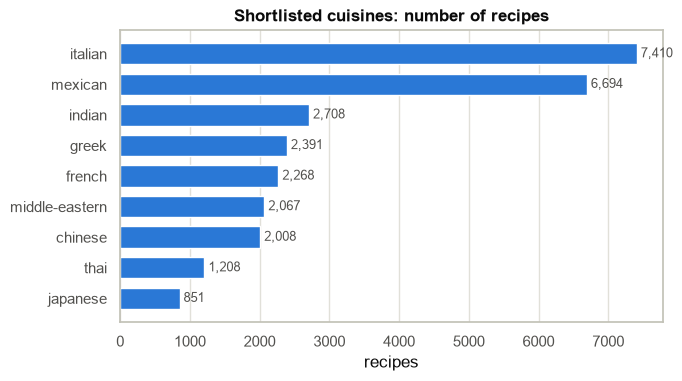

In [26]:
SHORTLIST = ["italian", "mexican", "indian", "greek", "french", "chinese", "middle-eastern", "thai", "japanese"]

member = pd.DataFrame({c: recipes["tags"].map(lambda ts, c=c: c in ts) for c in SHORTLIST})
n_short = member.sum(axis=1)
short_counts = pd.DataFrame({
    "recipes with tag": member.sum(),
    "only this shortlisted cuisine": member[n_short == 1].sum(),
    "reviews of these recipes": [reviews["recipe_id"].isin(recipes.loc[member[c], "id"]).sum() for c in SHORTLIST],
}).sort_values("recipes with tag", ascending=False)
display(short_counts)
print("recipes in at least one shortlisted cuisine:", (n_short >= 1).sum(),
      "| in two or more:", (n_short >= 2).sum())

fig, ax = plt.subplots(figsize=(7, 3.8))
s = short_counts["recipes with tag"].sort_values()
ax.barh(s.index, s.values, color=BLUE, height=0.7)
for y, v in enumerate(s.values):
    ax.text(v, y, f" {v:,}", va="center", fontsize=9, color="#52514e")
ax.set(title="Shortlisted cuisines: number of recipes", xlabel="recipes")
ax.grid(axis="y", visible=False)
save(fig, "06_shortlist_recipe_counts")
plt.show()

In [27]:
# Save the cuisine labels for later notebooks (data/processed is git-ignored)
out = recipes[["id", "specific_cuisines"]].copy()
out["specific_cuisines"] = out["specific_cuisines"].map("|".join)
for c in SHORTLIST:
    out[f"is_{c.replace('-', '_')}"] = member[c].values
out.to_csv(PROCESSED / "recipe_cuisines.csv", index=False)
print("saved data/processed/recipe_cuisines.csv", out.shape)

saved data/processed/recipe_cuisines.csv (231637, 11)


## 7. Ingredients
### 7.1 How many distinct ingredient strings, and which are most common?
We count each ingredient once per recipe (the frequency of an ingredient = the number of recipes it appears in).

In [28]:
ingr_freq = pd.Series(Counter(i for ings in recipes["ingredients"] for i in set(ings))).sort_values(ascending=False)
print("distinct ingredient strings:", len(ingr_freq))
print("recipe–ingredient pairs:", ingr_freq.sum())
print("strings used in exactly 1 recipe:", (ingr_freq == 1).sum(), f"({(ingr_freq == 1).mean():.1%})")
print("strings used in ≥ 10 recipes:", (ingr_freq >= 10).sum(), "| ≥ 100 recipes:", (ingr_freq >= 100).sum())
cum = ingr_freq.cumsum() / ingr_freq.sum()
print("strings needed to cover 90% of all recipe–ingredient pairs:", int((cum < 0.90).sum() + 1))

distinct ingredient strings: 14942
recipe–ingredient pairs: 2096582
strings used in exactly 1 recipe: 3546 (23.7%)
strings used in ≥ 10 recipes: 5984 | ≥ 100 recipes: 1840
strings needed to cover 90% of all recipe–ingredient pairs: 1449


saved figures/07_top30_ingredients.png


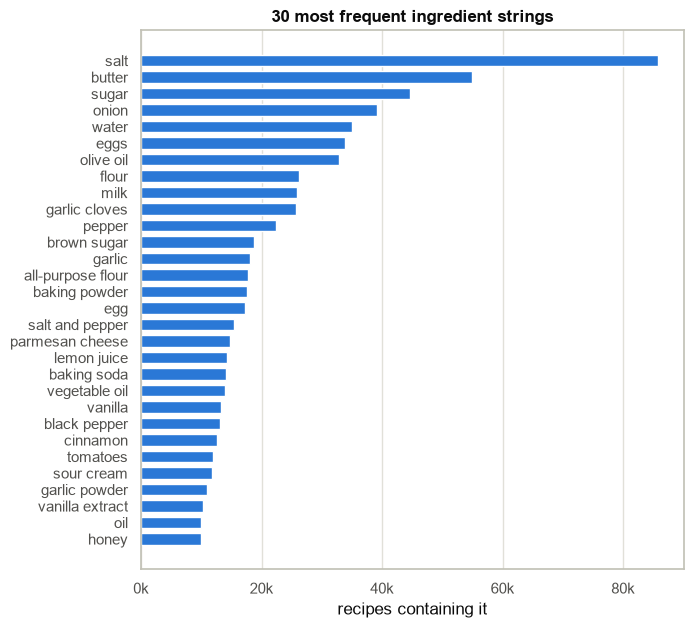

In [29]:
top30 = ingr_freq.head(30)
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(top30.index[::-1], top30.values[::-1], color=BLUE, height=0.7)
ax.set(title="30 most frequent ingredient strings", xlabel="recipes containing it")
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1e3:.0f}k"))
save(fig, "07_top30_ingredients")
plt.show()

### 7.2 Ingredient frequency distribution
Left: on linear axes almost everything is squeezed against 0. Middle: the same data on log–log axes (number of ingredient strings that appear in exactly *k* recipes). Right: the complementary cumulative distribution (share of strings that appear in *at least* *k* recipes), which is easier to read in the tail. A roughly straight line on log–log axes indicates a heavy-tailed distribution: a few ingredients are everywhere, most are rare.

saved figures/08_ingredient_frequency_distribution.png


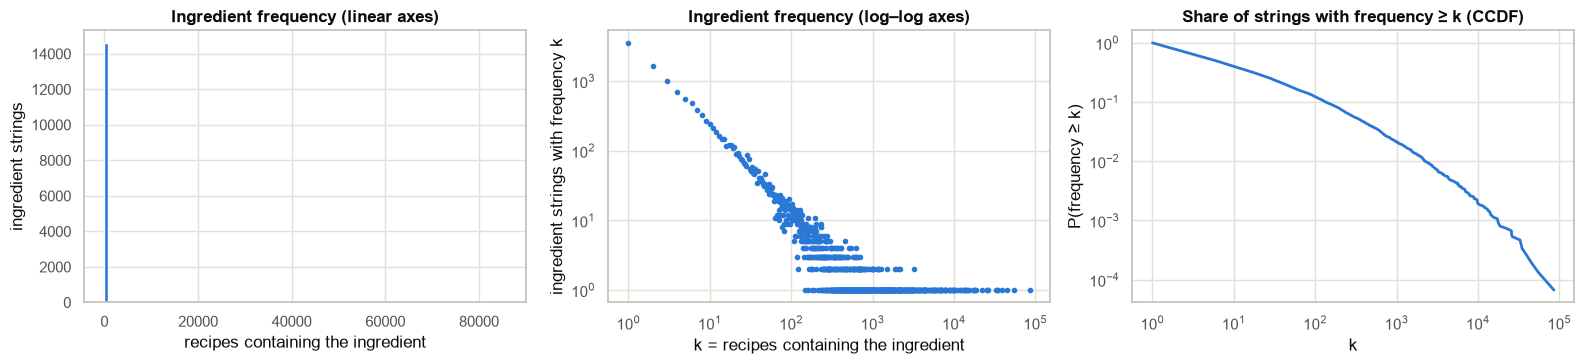

In [30]:
fk = ingr_freq.value_counts().sort_index()
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].hist(ingr_freq.values, bins=100, color=BLUE)
axes[0].set(title="Ingredient frequency (linear axes)", xlabel="recipes containing the ingredient", ylabel="ingredient strings")
axes[1].loglog(fk.index, fk.values, "o", ms=3, color=BLUE)
axes[1].set(title="Ingredient frequency (log–log axes)", xlabel="k = recipes containing the ingredient", ylabel="ingredient strings with frequency k")
ccdf = 1 - fk.cumsum().shift(fill_value=0) / fk.sum()
axes[2].loglog(ccdf.index, ccdf.values, "-", lw=2, color=BLUE)
axes[2].set(title="Share of strings with frequency ≥ k (CCDF)", xlabel="k", ylabel="P(frequency ≥ k)")
fig.tight_layout()
save(fig, "08_ingredient_frequency_distribution")
plt.show()

### 7.3 The normalisation problem: many strings for one ingredient
We do **not** normalise yet. We only show how many different strings contain a few common words, and two cheap indicators of how big the problem is.

In [31]:
KEYWORDS = ["garlic", "onion", "tomato", "egg", "butter", "parmesan", "olive oil", "chicken breast", "cilantro", "soy sauce"]
rows = []
for kw in KEYWORDS:
    hits = ingr_freq[ingr_freq.index.str.contains(rf"\b{kw}", regex=True)]
    rows.append({"keyword": kw, "distinct strings": len(hits), "recipes (sum)": hits.sum(),
                 "top variants": "; ".join(f"{k} ({v})" for k, v in hits.head(6).items())})
pd.DataFrame(rows).set_index("keyword")

,distinct strings,recipes (sum),top variants
keyword,,,
garlic,212,72372,garlic cloves (25748); garlic (18087); garlic powder (10887); garlic clove (...
onion,205,85489,onion (39065); onions (9872); green onions (5814); red onion (5777); green o...
tomato,309,42670,tomatoes (11950); tomato sauce (4402); tomato paste (4335); diced tomatoes (...
egg,114,66474,eggs (33761); egg (17304); egg whites (3258); egg yolks (2623); egg white (1...
butter,274,78241,butter (54975); unsalted butter (8935); buttermilk (3825); peanut butter (23...
parmesan,42,15492,parmesan cheese (14807); fresh parmesan cheese (413); fat-free parmesan chee...
olive oil,38,41597,olive oil (32822); extra virgin olive oil (7704); olive oil flavored cooking...
chicken breast,53,13753,boneless skinless chicken breasts (3994); chicken breasts (2793); boneless s...
cilantro,22,9595,fresh cilantro (4360); cilantro (3742); fresh cilantro leaves (521); cilantr...


In [32]:
idx = set(ingr_freq.index)
plural_pairs = [s for s in idx if s + "s" in idx]
fresh_pairs = [s for s in idx if "fresh " + s in idx]
print("strings X where 'X' and 'Xs' both exist (singular/plural):", len(plural_pairs), "e.g.", sorted(plural_pairs, key=lambda s: -ingr_freq[s])[:6])
print("strings X where 'X' and 'fresh X' both exist:            ", len(fresh_pairs), "e.g.", sorted(fresh_pairs, key=lambda s: -ingr_freq[s])[:6])
brand = ingr_freq[ingr_freq.index.str.contains(r"\b(?:kraft|knorr|campbell|pillsbury|hellmann|philadelphia|velveeta|bisquick|jell-o)\b", regex=True)]
print("strings containing a brand name (small hand-made brand list):", len(brand), "e.g.", list(brand.head(5).index))

strings X where 'X' and 'Xs' both exist (singular/plural): 1077 e.g. ['onion', 'egg', 'garlic clove', 'carrot', 'red onion', 'green onion']
strings X where 'X' and 'fresh X' both exist:             172 e.g. ['onion', 'water', 'garlic cloves', 'pepper', 'garlic', 'parmesan cheese']
strings containing a brand name (small hand-made brand list): 147 e.g. ['velveeta cheese', 'bisquick', 'bisquick baking mix', 'philadelphia cream cheese', 'strawberry jell-o gelatin dessert']


## 8. First network numbers (no community detection yet)
For each shortlisted cuisine we build two networks from the **raw** ingredient strings:

* **Bipartite recipe–ingredient network**: one node per recipe and one per ingredient string; an edge when the recipe uses the ingredient. Density = edges / (recipes × ingredients).
* **Ingredient co-occurrence projection**: one node per ingredient; an edge between two ingredients if they appear together in at least one recipe, weighted by the number of such recipes. Density = edges / (N(N−1)/2).

Because the projection connects every pair inside every recipe, it is very dense; we also report how many edges survive simple weight thresholds (w ≥ 2, w ≥ 5), which hints at how much backbone extraction will matter. These numbers will shrink once ingredients are normalised.

In [33]:
def cooccurrence(ingredient_lists):
    w = Counter()
    for ings in ingredient_lists:
        w.update(itertools.combinations(sorted(set(ings)), 2))
    return w

def network_stats(ingredient_lists, name):
    ingredient_lists = list(ingredient_lists)
    B = nx.Graph()
    rnodes = [("r", k) for k in range(len(ingredient_lists))]
    B.add_nodes_from(rnodes, bipartite=0)
    B.add_edges_from((("r", k), ("i", ing)) for k, ings in enumerate(ingredient_lists) for ing in set(ings))
    inodes = [n for n in B if n[0] == "i"]
    w = cooccurrence(ingredient_lists)
    G = nx.Graph()
    G.add_nodes_from(n[1] for n in inodes)
    G.add_weighted_edges_from((a, b, k) for (a, b), k in w.items())
    lcc = max(nx.connected_components(G), key=len)
    weights = np.fromiter(w.values(), dtype=int)
    return {
        "cuisine": name, "recipes": len(rnodes), "ingredients": len(inodes),
        "bip_edges": B.number_of_edges(), "bip_density": bipartite.density(B, rnodes),
        "proj_nodes": G.number_of_nodes(), "proj_edges": G.number_of_edges(), "proj_density": nx.density(G),
        "proj_edges_w>=2": int((weights >= 2).sum()), "proj_edges_w>=5": int((weights >= 5).sum()),
        "proj_mean_degree": 2 * G.number_of_edges() / G.number_of_nodes(),
        "proj_lcc_share": len(lcc) / G.number_of_nodes(),
        "ingredients_in_>=5_recipes": sum(1 for v in Counter(i for l in ingredient_lists for i in set(l)).values() if v >= 5),
    }

net_rows = [network_stats(recipes.loc[member[c], "ingredients"], c) for c in SHORTLIST]
net_rows.append(network_stats(recipes.loc[n_short >= 1, "ingredients"], "ALL SHORTLISTED"))
net = pd.DataFrame(net_rows).set_index("cuisine")
net.round({"bip_density": 5, "proj_density": 4, "proj_mean_degree": 1, "proj_lcc_share": 3})

,recipes,ingredients,bip_edges,bip_density,proj_nodes,proj_edges,proj_density,proj_edges_w>=2,proj_edges_w>=5,proj_mean_degree,proj_lcc_share,ingredients_in_>=5_recipes
cuisine,,,,,,,,,,,,
italian,7410,3720,75369,0.00273,3720,125359,0.0181,40690,13157,67.4,0.999,1211
mexican,6694,3478,67359,0.00289,3478,119390,0.0197,38680,12314,68.7,1.000,1136
indian,2708,2048,31414,0.00566,2048,66407,0.0317,21716,6753,64.9,1.000,654
greek,2391,2023,24278,0.00502,2023,51014,0.0249,15093,4400,50.4,1.000,549
french,2268,2447,20964,0.00378,2447,51649,0.0173,12427,3132,42.2,1.000,606
chinese,2008,1872,22036,0.00586,1872,49250,0.0281,14728,4275,52.6,1.000,534
middle-eastern,2067,1909,20264,0.00514,1909,46618,0.0256,12776,3510,48.8,0.998,522
thai,1208,1461,14088,0.00798,1461,41359,0.0388,11674,2940,56.6,1.000,433
japanese,851,1196,7377,0.00725,1196,20079,0.0281,4339,930,33.6,0.999,252


**Sanity check.** Our hand-rolled co-occurrence counting should give the same graph as NetworkX's own `bipartite.weighted_projected_graph`. We check this on the smallest cuisine.

In [34]:
c = net["recipes"].drop("ALL SHORTLISTED").idxmin()
lists = list(recipes.loc[member[c], "ingredients"])
B = nx.Graph()
B.add_edges_from((("r", k), ("i", ing)) for k, ings in enumerate(lists) for ing in set(ings))
P = bipartite.weighted_projected_graph(B, [n for n in B if n[0] == "i"])
w = cooccurrence(lists)
same = P.number_of_edges() == len(w) and all(P[("i", a)][("i", b)]["weight"] == k for (a, b), k in w.items())
print(f"{c}: NetworkX projection has {P.number_of_edges():,} edges; ours has {len(w):,}; identical weights: {same}")

japanese: NetworkX projection has 20,079 edges; ours has 20,079; identical weights: True


## 9. Text signals for our research questions
We attach to every review the shortlisted cuisine(s) of the recipe it reviews. A review of a recipe in two shortlisted cuisines is counted in both.

In [35]:
rv = reviews[["user_id", "recipe_id", "rating", "review"]].copy()
rv["text"] = rv["review"].fillna("").str.lower()
mem = member.copy()
mem["recipe_id"] = recipes["id"].values
rv = rv.merge(mem, on="recipe_id", how="left")
rv[SHORTLIST] = rv[SHORTLIST].fillna(False).astype(bool)

nltk.download("punkt_tab", quiet=True)  # sentence splitter model (stored in ~/nltk_data)
from nltk.tokenize import sent_tokenize

def example_sentences(texts, pattern, n=10, seed=RNG_SEED):
    rx = re.compile(pattern, re.IGNORECASE)
    out = []
    for t in texts.sample(min(len(texts), 200), random_state=seed):
        for s in sent_tokenize(t):
            if rx.search(s):
                out.append(s.strip()[:250])
                break
        if len(out) == n:
            break
    return out

def rate_by_cuisine(mask):
    rows = {c: (mask[rv[c]].sum(), rv[c].sum()) for c in SHORTLIST}
    rows["ALL REVIEWS"] = (mask.sum(), len(rv))
    df = pd.DataFrame(rows, index=["matching reviews", "reviews"]).T
    df["per 1,000 reviews"] = (df["matching reviews"] / df["reviews"] * 1000).round(2)
    return df.sort_values("per 1,000 reviews", ascending=False)

### 9.0 Reviews written for community cooking games
Many Food.com reviews start with "Made for ZWT4", "Made for PAC Spring 2010" or "Made for Photo Tag". These are site games: *Zaar World Tour* (ZWT) asks players to cook recipes from given countries, *Pick A Chef* (PAC), *Recipe Swap* and various *Tag* games ask them to cook and review each other's recipes. Such reviews may differ from ordinary ones (for example, ZWT pushes people towards foreign cuisines), so we measure how common they are per cuisine.

In [36]:
GAME = r"\bzwt ?\d*\b|zaar world tour|\bpac\b|pick a chef|\bswap\b|\btag\b|\bprmr\b|culinary quest|hit wonders"
game = rv["text"].str.contains(GAME, regex=True)
zwt = rv["text"].str.contains(r"\bzwt ?\d*\b|zaar world tour", regex=True)
print(f"reviews mentioning a community game: {game.sum():,} ({game.mean():.1%}); of which Zaar World Tour: {zwt.sum():,}")
game_table = pd.DataFrame({
    "% game reviews": {c: game[rv[c]].mean() * 100 for c in SHORTLIST} | {"ALL REVIEWS": game.mean() * 100},
    "% ZWT reviews": {c: zwt[rv[c]].mean() * 100 for c in SHORTLIST} | {"ALL REVIEWS": zwt.mean() * 100},
}).round(1).sort_values("% game reviews", ascending=False)
game_table

reviews mentioning a community game: 89,630 (7.9%); of which Zaar World Tour: 24,864


,% game reviews,% ZWT reviews
greek,14.1,9.7
french,13.1,6.8
middle-eastern,11.7,3.7
indian,9.3,4.5
thai,8.0,3.9
ALL REVIEWS,7.9,2.2
mexican,7.2,3.1
japanese,6.3,2.6
italian,6.2,1.8
chinese,5.7,1.8


### 9.1 "Authentic"
We match the word *authentic* and its forms (*authentically*, *authenticity*, *inauthentic*). This is a simple keyword match: it also catches negations ("not authentic") and other uses, which we will need to read or label by hand later.

reviews mentioning 'authentic': 3,463 of 1,132,367 (0.31%)
…of which contain 'not authentic' / 'inauthentic' / 'not very authentic' etc.: 255


,matching reviews,reviews,"per 1,000 reviews","per 1,000 non-game reviews"
thai,111,5633,19.71,20.85
indian,170,10875,15.63,16.12
middle-eastern,122,8884,13.73,14.53
japanese,65,4762,13.65,14.12
greek,162,13801,11.74,12.49
chinese,139,12138,11.45,11.97
mexican,392,40143,9.77,10.22
italian,224,43971,5.09,5.31
ALL REVIEWS,3463,1132367,3.06,3.14
french,29,10063,2.88,3.09


saved figures/09_authentic_by_cuisine.png


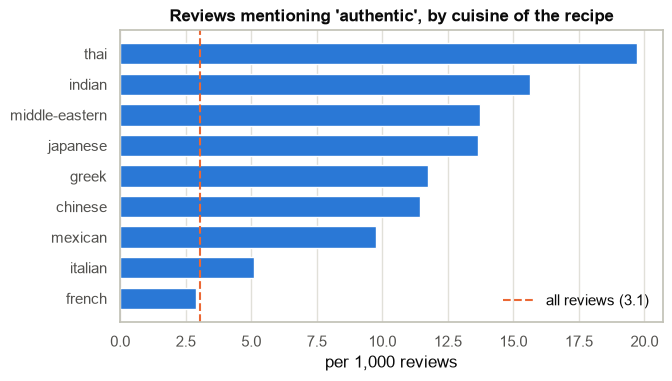

In [37]:
AUTH = r"\b(?:in)?authentic\w*"
auth = rv["text"].str.contains(AUTH, regex=True)
print(f"reviews mentioning 'authentic': {auth.sum():,} of {len(rv):,} ({auth.mean():.2%})")
print("…of which contain 'not authentic' / 'inauthentic' / 'not very authentic' etc.:",
      rv.loc[auth, "text"].str.contains(r"\b(?:not|isn'?t|wasn'?t|never|hardly)\s+(?:\w+\s+)?authentic|\binauthentic", regex=True).sum())
auth_table = rate_by_cuisine(auth)
auth_table["per 1,000 non-game reviews"] = pd.Series(
    {c: auth[rv[c] & ~game].mean() * 1000 for c in SHORTLIST} | {"ALL REVIEWS": auth[~game].mean() * 1000}).round(2)
display(auth_table)

fig, ax = plt.subplots(figsize=(7, 3.8))
s = auth_table.drop("ALL REVIEWS")["per 1,000 reviews"].sort_values()
ax.barh(s.index, s.values, color=BLUE, height=0.7)
base = auth_table.loc["ALL REVIEWS", "per 1,000 reviews"]
ax.axvline(base, color=ORANGE, ls="--", lw=1.5, label=f"all reviews ({base:.1f})")
ax.legend(loc="lower right", frameon=False)
ax.set(title="Reviews mentioning 'authentic', by cuisine of the recipe", xlabel="per 1,000 reviews")
ax.grid(axis="y", visible=False)
save(fig, "09_authentic_by_cuisine")
plt.show()

In [38]:
for s in example_sentences(rv.loc[auth & (rv[SHORTLIST].any(axis=1)), "review"].dropna(), AUTH):
    print("-", s)

- Very easy and authentic.
- I'll be making these VERY often, and next time will probably try the 1/2 beef 1/2 lamb combination for even more authentic Greek flavor.
- This recipe was simple, yet it very authentic!
- good, but more authentic if you make and season your own beans.
- Great authentic flavor.
- This tastes like an authentic soup you would get at a restaurant.
- Perfect flavoring and the most authentic that my BF has had in a long time.
- Tasted very authentic.
- Good recipe and very authentic as is.
- ), and this recipe reminds me of the authentic Pozole I had down there!


### 9.2 Substitutions
Phrases that usually signal that the reviewer changed an ingredient. A review can match several patterns. We do not match the bare word *swap*, because on Food.com it mostly refers to "Recipe Swap" games ("Made for Aussie/NZ Swap"). *Instead of* also catches non-ingredient changes ("baked instead of fried"), so these counts are an upper bound.

In [39]:
SUBST = {
    "instead of": r"\binstead of\b",
    "substitut(e/ed/ing/ion)": r"\bsubstitut(?:e|ed|es|ing|ion|ions)\b",
    "subbed": r"\bsubbed\b",
    "replaced/replace … with": r"\breplac(?:e|ed|ing)\b[^.!?]{0,60}?\bwith\b",
    "swapped/swapping": r"\bswapp(?:ed|ing)\b",  # not "swap": on Food.com that is usually a "Recipe Swap" game
    "in place of": r"\bin place of\b",
}
hits = pd.DataFrame({k: rv["text"].str.contains(p, regex=True) for k, p in SUBST.items()})
subst = hits.any(axis=1)
display(hits.sum().rename("reviews").to_frame().assign(pct=lambda d: (d["reviews"] / len(rv) * 100).round(2)))
print(f"reviews with at least one substitution phrase: {subst.sum():,} ({subst.mean():.1%})")
display(rate_by_cuisine(subst))
print(f"share of substitution reviews that use 'instead of' only: {(hits['instead of'] & (hits.sum(axis=1) == 1)).sum() / subst.sum():.1%}")
print("mean rating with vs. without a substitution phrase (ratings 1–5 only):",
      rv[rv["rating"] > 0].groupby(subst[rv["rating"] > 0])["rating"].mean().round(3).to_dict())

,reviews,pct
instead of,88638,7.83
substitut(e/ed/ing/ion),29920,2.64
subbed,7752,0.68
replaced/replace … with,4665,0.41
swapped/swapping,494,0.04
in place of,12703,1.12


reviews with at least one substitution phrase: 134,991 (11.9%)


,matching reviews,reviews,"per 1,000 reviews"
thai,921,5633,163.50
indian,1570,10875,144.37
chinese,1657,12138,136.51
italian,5603,43971,127.42
mexican,5064,40143,126.15
middle-eastern,1111,8884,125.06
ALL REVIEWS,134991,1132367,119.21
japanese,546,4762,114.66
greek,1546,13801,112.02
french,1075,10063,106.83


share of substitution reviews that use 'instead of' only: 60.2%
mean rating with vs. without a substitution phrase (ratings 1–5 only): {False: 4.655, True: 4.711}


In [40]:
SUBST_ANY = "|".join(SUBST.values())
for s in example_sentences(rv.loc[subst, "review"].dropna(), SUBST_ANY):
    print("-", s)

- The only substitution I made was instead of tomato paste, I used Manwich Bold.
- I only made one change and that was to use baby portabellas in place of the dried ones.
- This was excellent, I made one substitution.
- I used  Recipe #66591 for the taco seasoning, instead of store bought one, which worked fine.
- I used fideo instead of spaghetti and Better Than Bouillon for the broth - I highly recommend both for that authentic Rice-a-Roni taste.
- I doubled the filling amount and used diced apples instead of shredded.
- I used scallions instead of onions, used a package of oriental roman noodles (added the flavor package to dressing), used almonds in place of walnuts, added some sesame seeds and sauteed the nuts and noodles in sesame oil.
- Since I had read about the blackberry substitution, I decided to try that, only I used fresh blackberries and blackberry preserves.
- Used mini marshmallows instead of large, which worked great.
- I had a similar recipe that used butter instead o

## Key findings and open questions

**Numbers that matter for choosing our research questions**

- **Scale.** 231,637 recipes (submitted 1999–2018) and 1,132,367 reviews (2000–2018) by 226,570 users. Every recipe has at least one review (median 2, 99th percentile 47). Activity peaked in 2007–2009; after 2013 fewer than 1,100 recipes per year were submitted, so any analysis over time is really about 2002–2012.
- **Cuisine labels exist for a minority of recipes.** We found 108 cuisine/region tags from the tag hierarchy itself (no hand-made list). 60.7% of recipes have no cuisine tag, 30.2% have exactly one specific cuisine, and 9.1% have two or more. Most of the multi-cuisine cases are a country plus a region the site did not link as parent (e.g. `mexican` + `north-american`: 4,517), not real fusion recipes.
- **Shortlist of 9 cuisines** with 27,160 recipes in total and little overlap (431 recipes in two of them): italian 7,410 · mexican 6,694 · indian 2,708 · greek 2,391 · french 2,268 · middle-eastern 2,067 · chinese 2,008 · thai 1,208 · japanese 851. Reviews per cuisine range from 4,762 (japanese) to 43,971 (italian).
- **Network size fits the course guideline before cleaning.** Per cuisine, the recipe–ingredient network has 1,196 (japanese) to 3,720 (italian) ingredient nodes; all 9 together have 7,337. The co-occurrence projection is dense and almost fully connected (largest component ≥ 99.8% of nodes, mean degree 34–69). Only 5–10% of its edges have weight ≥ 5 (italian: 13,157 of 125,359; japanese: 930 of 20,079), so we will need a backbone or threshold before community detection, and modularity must be compared against a null model.
- **"Authentic" is rare but clearly uneven across cuisines.** 3,463 reviews (0.31%) contain it. Per 1,000 reviews: thai 19.7, indian 15.6, middle-eastern 13.7, japanese 13.7, greek 11.7, chinese 11.5, mexican 9.8, italian 5.1, french 2.9, all reviews 3.1. The ranking is the same without game reviews. The absolute numbers are small (29 french to 392 mexican), and 255 matches are negations ("not authentic"), so this needs hand-labelled examples rather than only counts.
- **Substitution language is common.** 134,991 reviews (11.9%) contain a substitution phrase, from 107 per 1,000 (french) to 164 (thai). 60% of these match only "instead of", which is noisy (it also catches "baked instead of fried"). Reviews with a substitution phrase have a slightly *higher* mean rating (4.71 vs. 4.66). This is a large enough signal to extract *which* ingredient replaces which, which could become a substitution network.

**Main data problems**

- **Ingredient strings are not normalised.** There are 14,942 distinct strings; 23.7% occur in a single recipe, and 1,449 strings cover 90% of all uses. "garlic" appears in 212 different strings, 1,077 strings also exist with an added "s", 172 also exist with "fresh " in front, and at least 147 contain a brand name. Normalisation will change every network number above. The full Kaggle dataset ships an `ingr_map.pkl` from the paper's authors that maps raw strings to canonical ingredients; we should evaluate it before writing our own rules.
- **Ratings carry little variation.** 72.1% of reviews are 5 stars and 16.5% are 4 stars. A rating of 0 (5.4% of reviews) is not a bad rating. It most likely means "no stars given": these reviews contain a question mark 3.7× as often (10.6% vs. 2.9%), and several of the sampled examples say so explicitly. We should treat 0 as missing.
- **Community cooking games.** 7.9% of reviews were written for site games (Zaar World Tour, Pick A Chef, Recipe Swap, Tag games), rising to 14.1% for greek and 13.1% for french. Zaar World Tour sends players to foreign cuisines on purpose, which could bias cuisine-level text comparisons.
- **Outliers and noise.** `minutes` goes up to 2,147,483,647 (the largest 32-bit integer, so clearly a placeholder), 2,000 recipes claim more than one day, and 1,094 claim 0 minutes. Nutrition has impossible values (up to 434,360 calories). 2,881 recipes share a name with another recipe. 73% of users wrote only one review, so user-level networks will be very sparse.

**Open questions for the team**

1. Do we use `ingr_map.pkl`, our own rules, or both (and compare them as a robustness check)?
2. Do we keep `american` as a baseline cuisine, and what do we do with the 3,921 recipes tagged only `asian`?
3. Do we exclude game reviews from the NLP part, or keep them and control for them?
4. Who hand-labels a sample of "authentic" and substitution sentences so that we can check the keyword counts?